# Hamburg accommodation study – validation notebook

**Purpose:** check the data in `hamburg_maps_search_study.xlsx` and reproduce the key figures from the Excel workbook independently in Python.

- **Data:** 6 Google Maps searches around Hamburg (collected 17 Nov 2026), top 20 regular results each, plus ads → 116 search rows, 99 unique properties.
- **Prices:** stay Fri 11 – Sun 13 Dec 2026, 2 adults, per night; direct (hotel website) vs. Booking.com, checked 17–22 Nov 2026.
- **Gap definition:** (Booking.com − direct) / direct → positive = Booking.com more expensive.

## 1. Load the data

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
FILE = "hamburg_maps_search_study.xlsx"
print(pd.ExcelFile(FILE).sheet_names)

searches = pd.read_excel(FILE, sheet_name="Searches")
props = pd.read_excel(FILE, sheet_name="Properties")
print(searches.shape, props.shape)

['Notes', 'Dashboard', 'Pivot_Ads', 'Pivot_Types', 'Searches', 'website by type', 'Pivot_Gap', 'Properties']
(116, 19) (99, 27)


In [3]:
print("Searches columns:", list(searches.columns))
print("Props columns:", list(props.columns))

display(searches.head())
display(props.head())

Searches columns: ['query', 'rank', 'sponsored', 'property_id', 'name', 'google_category', 'stars', 'rating', 'review_count', 'sleeps', 'bedrooms', 'maps_price_eur_night', 'address', 'has_website', 'place_id', 'lat', 'lon', 'offer_type', 'note']
Props columns: ['property_id', 'name', 'offer_type', 'to_price', 'google_category', 'stars', 'rating', 'review_count', 'sleeps', 'bedrooms', 'address', 'place_id', 'lat', 'lon', 'searches', 'n_searches', 'best_rank', 'maps_price_eur_night', 'has_website', 'price_direct', 'price_direct_member', 'price_booking', 'price_airbnb', 'price_notes', 'cheapest_channel', 'gap_pct', 'hotel_group']


,query,rank,sponsored,property_id,name,google_category,stars,rating,review_count,sleeps,bedrooms,maps_price_eur_night,address,has_website,place_id,lat,lon,offer_type,note
0,holiday apartments near hamburg,1.0,no,P001,Cosy 2-room Apartment in urban location,Apartment,NaN,3.8,49.0,7.0,NaN,144.0,NaN,NaN,ChIJGQLw5hOJsUcRUGhG1pzCgRY,53.604454,10.043011,short-stay apartment,"5 beds, bedrooms not shown"
1,holiday apartments near hamburg,2.0,no,P002,Clipper Boardinghouse - Hamburg-Michel - Comfo...,Apartment,NaN,5.0,8.0,2.0,1.0,271.0,NaN,NaN,ChIJryhuXg6PsUcRIXykDbL1CE8,53.546249,9.977600,short-stay apartment,NaN
2,holiday apartments near hamburg,3.0,no,P003,Apartment EG - Apartment,Apartment,NaN,5.0,16.0,3.0,1.0,130.0,NaN,NaN,ChIJK1ecOMiMsUcRzhQjot4_Id0,53.542320,10.165390,short-stay apartment,NaN
3,holiday apartments near hamburg,4.0,no,P004,Urban Rooftop,Apartment,NaN,2.7,10.0,3.0,1.0,85.0,NaN,NaN,ChIJb3gWC1qMsUcRsGrZ0aanBAU,53.538002,10.106585,short-stay apartment,NaN
4,holiday apartments near hamburg,5.0,no,P005,Apartment am Michel mit Parkplatz,Apartment,NaN,4.7,15.0,2.0,1.0,251.0,NaN,NaN,ChIJ71qh2Q-PsUcRrENVkUDeWR8,53.548145,9.981176,short-stay apartment,NaN


,property_id,name,offer_type,to_price,google_category,stars,rating,review_count,sleeps,bedrooms,...,maps_price_eur_night,has_website,price_direct,price_direct_member,price_booking,price_airbnb,price_notes,cheapest_channel,gap_pct,hotel_group
0,P001,Cosy 2-room Apartment in urban location,short-stay apartment,yes,Apartment,NaN,3.8,49.0,7.0,NaN,...,144.0,no,NaN,NaN,NaN,NaN,no own website; Maps price (€144) via Booking.com,NaN,NaN,NaN
1,P002,Clipper Boardinghouse - Hamburg-Michel - Comfo...,short-stay apartment,yes,Apartment,NaN,5.0,8.0,2.0,1.0,...,271.0,yes,237.0,NaN,343.0,NaN,"11–13 Dec; flexible rate; incl. VAT, fees and ...",price_direct,0.447257,apartment
2,P003,Apartment EG - Apartment,short-stay apartment,yes,Apartment,NaN,5.0,16.0,3.0,1.0,...,130.0,no,NaN,NaN,NaN,NaN,no own website; Maps price (€130) via BluePill...,NaN,NaN,NaN
3,P004,Urban Rooftop,short-stay apartment,yes,Apartment,NaN,2.7,10.0,3.0,1.0,...,85.0,no,NaN,NaN,NaN,NaN,no own website; Maps price (€85) via Booking.c...,NaN,NaN,NaN
4,P005,Apartment am Michel mit Parkplatz,short-stay apartment,yes,Apartment,NaN,4.7,15.0,2.0,1.0,...,251.0,no,NaN,NaN,NaN,NaN,no own website; Maps price (€251) via Booking....,NaN,NaN,NaN


## 2. Validation checks

In [4]:
dupes = props["property_id"].duplicated().sum()

if dupes == 0:
    print("Check 1 – unique IDs: PASS")
else:
    print(f"Check 1 – unique IDs: FAIL ({dupes} duplicates)")

Check 1 – unique IDs: PASS


In [5]:
missing = (~searches["property_id"].isin(props["property_id"])).sum()

if missing == 0:
    print("Check 2 – all search results exist in props: PASS")
else:
    print(f"Check 2 – missing properties: FAIL ({missing} missing)")

Check 2 – all search results exist in props: PASS


In [6]:
# Check 3 – results per search without ads (expected: 20 each; holiday apartments 19 and guest houses 5 = end of list)
organic_searches = searches[searches["sponsored"] == "no"]
results_per_query = organic_searches.groupby("query").size()
print(results_per_query)

query
guest houses near hamburg           5
holiday apartments near hamburg    19
hotels near hamburg                20
luxury hotels near hamburg         20
rent apartments near hamburg       20
rent houses near hamburg           20
dtype: int64


In [7]:
# Check 4 – plausible prices (EUR per night). Empty cells (NaN) are ignored automatically.
price_cols = ["price_direct", "price_direct_member", "price_booking"]

all_ok = True

for col in price_cols:
    weird_rows = props[(props[col] <= 0) | (props[col] > 1000)]
    weird_count = len(weird_rows)

    if weird_count > 0:
        all_ok = False
        print(f"Column '{col}' has {weird_count} implausible price(s)")

if all_ok:
    print("Check 4 – plausible prices: PASS")
else:
    print("Check 4 – plausible prices: FAIL")

Check 4 – plausible prices: PASS


In [8]:
# Check 5 – data flags (counts for the README)
# "contains" instead of "startswith": in one row (P022) the DATES flag is not at the start of the note
dates_mask = props["price_notes"].str.contains("DATES", na=False)
dates_count = dates_mask.sum()

not_sampled_count = (props["price_notes"] == "not sampled (time)").sum()

print("Rows priced on other dates (DATES):", dates_count)
print("Rows marked 'not sampled (time)':", not_sampled_count)

display(props.loc[dates_mask, ["property_id", "price_notes"]])

Rows priced on other dates (DATES): 6
Rows marked 'not sampled (time)': 20


,property_id,price_notes
19,P020,DATES 13–15 Dec (11–13 not available); 2 adult...
21,P022,"own website but booking only via enquiry, no o..."
40,P041,DATES 13–15 Dec (11–13 fully booked); Standard...
42,P043,DATES 13–15 Dec (11–13 only business rooms); S...
45,P046,DATES 13–15 Dec (11–13 not available); Standar...
49,P050,DATES 13–15 Dec; 2 adults; ROOMS DIFFER: direc...


## 3. Recalculate the price gap and compare with Excel

In [9]:
props["gap_check"] = props["price_booking"] / props["price_direct"] - 1

display(props[["property_id", "price_direct", "price_booking", "gap_check"]].head(10))

,property_id,price_direct,price_booking,gap_check
0,P001,NaN,NaN,NaN
1,P002,237.0,343.0,0.447257
2,P003,NaN,NaN,NaN
3,P004,NaN,NaN,NaN
4,P005,NaN,NaN,NaN
5,P006,NaN,NaN,NaN
6,P007,NaN,NaN,NaN
7,P008,NaN,177.0,NaN
8,P009,NaN,NaN,NaN
9,P010,NaN,NaN,NaN


In [10]:
gap_pct_numeric = pd.to_numeric(props["gap_pct"], errors="coerce")

max_diff = (props["gap_check"] - gap_pct_numeric).abs().max()
print("Max difference:", max_diff)

if max_diff < 1e-9:
    print("Gap matches Excel: PASS")
else:
    print("Gap matches Excel: FAIL")

Max difference: 0.0
Gap matches Excel: PASS


In [11]:
filtered = props[props["hotel_group"].isin(["chain", "independent"])]

summary = filtered.groupby("hotel_group")["gap_check"].agg(["median", "mean", "count"])
print(summary)

print("\nAs percentages (%):")
print((summary[["median", "mean"]] * 100).round(1))

               median      mean  count
hotel_group                           
chain        0.022507  0.035323     10
independent  0.067580  0.111050      6

As percentages (%):
             median  mean
hotel_group              
chain           2.3   3.5
independent     6.8  11.1


## 4. Spread per hotel

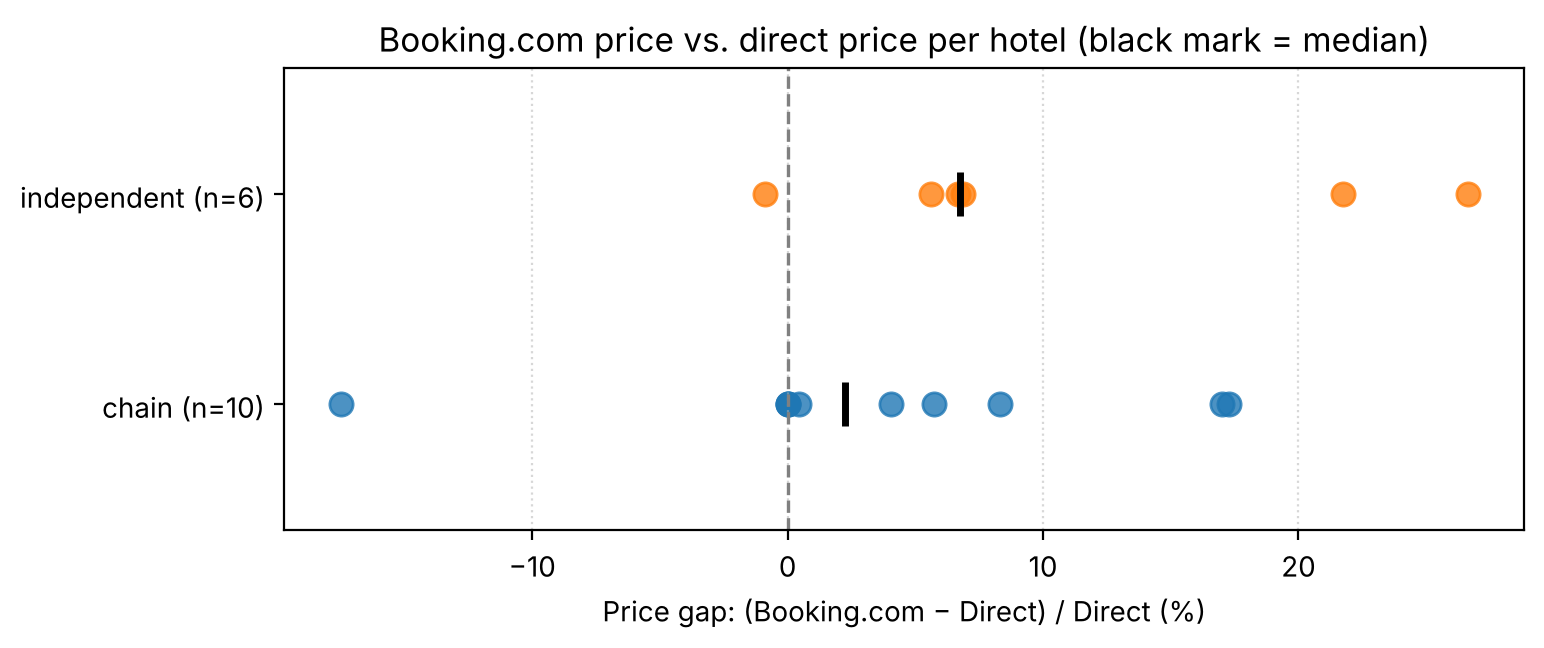

In [12]:
groups = ["chain", "independent"]
labels = []

plt.figure(figsize=(8, 3))

for i, grp in enumerate(groups):
    vals = filtered.loc[filtered["hotel_group"] == grp, "gap_check"].dropna() * 100
    labels.append(f"{grp} (n={len(vals)})")

    plt.scatter(vals, [i] * len(vals), alpha=0.8, s=70)

    med_val = vals.median()
    plt.scatter([med_val], [i], marker="|", s=250, linewidths=2.5, color="black")

plt.axvline(0, linestyle="--", linewidth=1.2, color="gray")

plt.yticks([0, 1], labels)
plt.ylim(-0.6, 1.6)
plt.xlabel("Price gap: (Booking.com − Direct) / Direct (%)")
plt.title("Booking.com price vs. direct price per hotel (black mark = median)")
plt.grid(axis="x", linestyle=":", alpha=0.5)

plt.savefig("gap_by_hotel.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Conclusion

All structural and price-sanity checks passed across the 116 search rows and 99 properties, and the gap recalculated in Python matched the Excel `gap_pct` column exactly. The gap is defined as (Booking.com − direct) / direct, so positive values mean Booking.com was more expensive. For hotels with both a public direct price and a Booking.com price, independent hotels (n=6) showed a higher median gap (6.8%) than chain hotels (n=10, 2.3%); most chains sat close to parity (7 of 10 between 0% and 8%), and their direct advantage was often limited to member rates. These results apply to a small sampled subset (16 hotels, one stay, prices checked 17–22 Nov; 3 hotels priced for 13–15 Dec) and should be read as indicative, not representative of all Hamburg hotels.